# Midterm Project – Deep Learning
## Part 2: CNN for Supermarket Shelf Item Classification

**Task:** Classify annotated image regions as `Product` or `Price` using a convolutional neural network (CNN). The supplied dataset contains supermarket shelf photographs and rectangle annotations, rather than plant-leaf class folders. This notebook therefore crops each annotated rectangle and trains a CNN on those crops. It is a crop-classification task, not a complete object detector that predicts boxes on a new full image.

**Dataset:** `Supermarket shelves.zip` (45 shelf images with JSON rectangle annotations).

**Google Colab:** choose a GPU runtime if available, upload the ZIP when prompted, then run all cells. The train/validation/test split is performed by original image, so crops from the same photograph cannot leak across splits. Because the dataset is small, results should be treated as preliminary.


**Deliverables:** this notebook trains and evaluates the CNN, saves `supermarket_shelf_cnn.joblib`, and demonstrates inference on image crops and selected shelf regions.

## 1. Imports and configuration

In [ ]:
import os, json, glob, zipfile, time, random
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 20
CLASS_NAMES = ['Price', 'Product']
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Upload and extract the dataset

In [ ]:
# Upload, validate, and extract the dataset (run this cell once)
import os, shutil, zipfile
from google.colab import files

ZIP_PATH = "/content/Supermarket shelves.zip"
DATA_DIR = "/content/supermarket_dataset"

# Reuse the existing archive only if it is a valid ZIP.
if not os.path.exists(ZIP_PATH) or not zipfile.is_zipfile(ZIP_PATH):
    if os.path.exists(ZIP_PATH):
        os.remove(ZIP_PATH)
    print("Please upload the original Supermarket shelves.zip file.")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file was uploaded.")
    uploaded_name = next(iter(uploaded))
    with open(ZIP_PATH, "wb") as f:
        f.write(uploaded[uploaded_name])

# Validate the archive before extraction.
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(
        "The uploaded file is not a valid ZIP archive. "
        "Re-download the original ZIP and upload it again."
    )

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_member = zf.testzip()
    if bad_member is not None:
        raise ValueError(f"ZIP integrity check failed at: {bad_member}")
    # Start with a clean extraction folder to avoid stale/mixed files.
    if os.path.isdir(DATA_DIR):
        shutil.rmtree(DATA_DIR)
    os.makedirs(DATA_DIR, exist_ok=True)
    zf.extractall(DATA_DIR)

print("ZIP validated and extracted successfully.")
print("Dataset directory:", DATA_DIR)
print("Top-level contents:", os.listdir(DATA_DIR))


Please upload the original Supermarket shelves.zip file.


Saving Supermarket shelves.zip to Supermarket shelves.zip
ZIP validated and extracted successfully.
Dataset directory: /content/supermarket_dataset
Top-level contents: ['__MACOSX', 'Supermarket shelves']


### Note
The upload, ZIP validation, and extraction are handled in Section 2 above. Do not delete or upload the ZIP again in separate cells unless the archive is invalid.

The dataset should be uploaded only once. If re-upload is needed, rerun the unified upload/extraction cell in Section 2.

The unified upload/extraction cell verifies the ZIP archive before extracting it.

The dataset is extracted to `/content/supermarket_dataset`; the annotation parser below searches nested folders for `images` and `annotations`.

In [ ]:
import os
import json
import numpy as np
from PIL import Image
from collections import Counter

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
SEARCH_ROOT = "/content/supermarket_dataset"

image_by_name = {}
annotation_files = []

# Search recursively because the ZIP contains nested folders
for root, dirs, files in os.walk(SEARCH_ROOT):
    dirs[:] = [
        d for d in dirs
        if d != "__MACOSX" and d != ".ipynb_checkpoints"
    ]

    folder_name = os.path.basename(root).lower()

    for fn in files:
        full_path = os.path.join(root, fn)
        lower_name = fn.lower()

        if folder_name == "images" and lower_name.endswith(IMG_EXT):
            image_by_name[fn] = full_path

        elif folder_name == "annotations" and lower_name.endswith(".json"):
            annotation_files.append(full_path)

print("Images found:", len(image_by_name))
print("Annotation files found:", len(annotation_files))

if not image_by_name or not annotation_files:
    raise FileNotFoundError(
        "Images or annotations were not found. "
        "Check that the ZIP has been extracted under /content."
    )

# Match annotations such as 035.jpg.json with image 035.jpg
records = []
per_class = Counter()
matched_pairs = 0
unmatched_annotations = []

for ann_path in sorted(annotation_files):
    image_name = os.path.basename(ann_path)[:-5]
    img_path = image_by_name.get(image_name)

    if img_path is None:
        unmatched_annotations.append(image_name)
        continue

    with open(ann_path, "r", encoding="utf-8") as f:
        ann = json.load(f)

    matched_pairs += 1

    with Image.open(img_path) as source:
        im = source.convert("RGB")
        width, height = im.size

        for obj in ann.get("objects", []):
            label = obj.get("classTitle", "").strip()

            if label not in CLASS_TO_ID:
                continue

            corners = obj.get("points", {}).get("exterior", [])
            if len(corners) < 2:
                continue

            x1, y1 = corners[0]
            x2, y2 = corners[1]

            x1 = int(np.clip(x1, 0, width))
            x2 = int(np.clip(x2, 0, width))
            y1 = int(np.clip(y1, 0, height))
            y2 = int(np.clip(y2, 0, height))

            left, right = sorted((x1, x2))
            top, bottom = sorted((y1, y2))

            if right - left < 2 or bottom - top < 2:
                continue

            crop = im.crop(
                (left, top, right, bottom)
            ).resize((IMG_SIZE, IMG_SIZE))

            records.append({
                "image_name": image_name,
                "label": label,
                "label_id": CLASS_TO_ID[label],
                "crop": np.asarray(crop)
            })

            per_class[label] += 1

print("Matched image-annotation pairs:", matched_pairs)
print(
    "Source images with valid crops:",
    len(set(r["image_name"] for r in records))
)
print("Total valid annotated crops:", len(records))
print("Crop counts by class:", dict(per_class))

if unmatched_annotations:
    print("Unmatched annotation examples:", unmatched_annotations[:5])

if not records or len(per_class) < 2:
    raise ValueError(
        "Both Product and Price classes were not found. "
        "Check the printed image and annotation counts."
    )

print("SUCCESS: Both classes are ready for CNN training!")

Images found: 45
Annotation files found: 45
Matched image-annotation pairs: 45
Source images with valid crops: 45
Total valid annotated crops: 11656
Crop counts by class: {'Product': 9910, 'Price': 1746}
SUCCESS: Both classes are ready for CNN training!


## 3. Read rectangle annotations and create labelled crops

Each annotation JSON contains the class title and two exterior rectangle corners. We crop the corresponding region from the original photograph and use the annotation title (`Price` or `Product`) as its label. Invalid or empty boxes are skipped.

## 4. Explore the annotated data

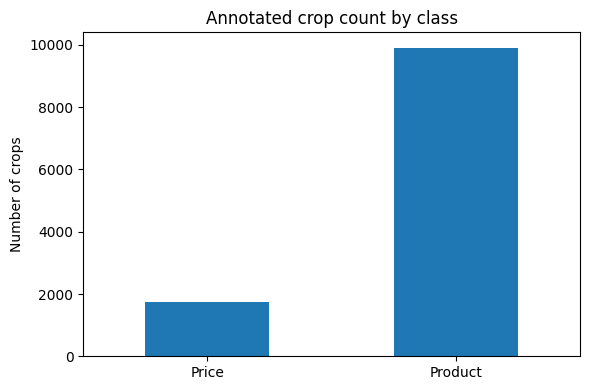

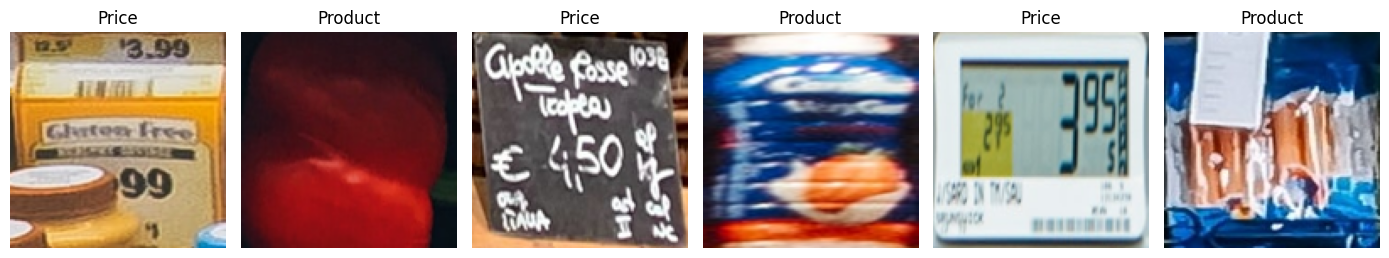

In [ ]:
# Explore class counts and display examples safely
count_series = pd.Series(per_class).reindex(CLASS_NAMES, fill_value=0)
ax = count_series.plot(kind='bar', figsize=(6, 4), rot=0)
ax.set_title('Annotated crop count by class')
ax.set_ylabel('Number of crops')
plt.tight_layout()
plt.show()

available_labels = [label for label in CLASS_NAMES
                    if any(r['label'] == label for r in records)]
if not available_labels:
    print("No labelled crops are available to visualize. Re-run the annotation parsing cell.")
else:
    fig, axes = plt.subplots(1, min(6, len(available_labels) * 3),
                             figsize=(14, 3))
    axes = np.atleast_1d(axes)
    rng = np.random.default_rng(SEED)
    for i, ax in enumerate(axes):
        label = available_labels[i % len(available_labels)]
        choices = [r for r in records if r['label'] == label]
        sample = choices[int(rng.integers(0, len(choices)))]
        ax.imshow(sample['crop'])
        ax.set_title(label)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


## 5. Split by original photograph and build TensorFlow datasets

The split is grouped by source image rather than by crop. This avoids putting crops from one shelf photograph into both training and test sets. All crops are resized to 128×128 RGB. Pixel values are scaled to [0, 1] inside the model. Augmentation is used only while training.

In [ ]:
source_images = np.array(sorted(set(r['image_name'] for r in records)))
# Split source images first; all crops from one image stay in one partition.
train_imgs, temp_imgs = train_test_split(source_images, test_size=0.30, random_state=SEED)
val_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.50, random_state=SEED)
train_set, val_set, test_set = set(train_imgs), set(val_imgs), set(test_imgs)
train_records = [r for r in records if r['image_name'] in train_set]
val_records = [r for r in records if r['image_name'] in val_set]
test_records = [r for r in records if r['image_name'] in test_set]

def arrays(rows):
    X = np.stack([r['crop'] for r in rows]).astype('uint8')
    y = np.array([r['label_id'] for r in rows], dtype='int32')
    return X, y
X_train, y_train = arrays(train_records)
X_val, y_val = arrays(val_records)
X_test, y_test = arrays(test_records)
print('Source images (train/val/test):', len(train_imgs), len(val_imgs), len(test_imgs))
print('Annotated crops (train/val/test):', len(y_train), len(y_val), len(y_test))
print('Train class counts:', {n: int((y_train == i).sum()) for i, n in enumerate(CLASS_NAMES)})

augment = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name='augmentation')

def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(min(len(y), 10000), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test, y_test)


Source images (train/val/test): 31 7 7
Annotated crops (train/val/test): 8594 1696 1366
Train class counts: {'Price': 1271, 'Product': 7323}


## 6. CNN architecture

A four-block CNN extracts visual features from each annotated crop. Global average pooling limits the classifier size; dropout and augmentation help reduce overfitting. The softmax output has two classes: `Price` and `Product`.

In [ ]:
def build_cnn():
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(CLASS_NAMES), activation='softmax')(x)
    model = keras.Model(inp, out, name='supermarket_crop_cnn')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_cnn()
model.summary()
class_ids = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=class_ids, y=y_train)
class_weights = {int(k): float(v) for k, v in zip(class_ids, weights)}
print('Class weights:', class_weights)


Model: "supermarket_crop_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,010 (1.61 MB)

 Trainable params: 422,050 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Class weights: {0: 3.3808025177025964, 1: 0.586781373753926}


## 7. Train the CNN

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint('best_supermarket_cnn.keras', monitor='val_loss', save_best_only=True),
]
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=callbacks, class_weight=class_weights, verbose=2)
training_minutes = (time.time() - t0) / 60
print(f'Training time: {training_minutes:.2f} minutes; epochs run: {len(history.history["loss"])}')


Epoch 1/20
269/269 - 21s - 78ms/step - accuracy: 0.7892 - loss: 0.4597 - val_accuracy: 0.4045 - val_loss: 0.7898 - learning_rate: 0.0010
Epoch 2/20
269/269 - 12s - 45ms/step - accuracy: 0.8184 - loss: 0.3897 - val_accuracy: 0.7842 - val_loss: 0.4055 - learning_rate: 0.0010
Epoch 3/20
269/269 - 12s - 44ms/step - accuracy: 0.8259 - loss: 0.3825 - val_accuracy: 0.7553 - val_loss: 0.5063 - learning_rate: 0.0010
Epoch 4/20

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
269/269 - 12s - 45ms/step - accuracy: 0.8390 - loss: 0.3562 - val_accuracy: 0.7877 - val_loss: 0.4750 - learning_rate: 0.0010
Epoch 5/20
269/269 - 12s - 46ms/step - accuracy: 0.8540 - loss: 0.3288 - val_accuracy: 0.7712 - val_loss: 0.4088 - learning_rate: 5.0000e-04
Epoch 6/20

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
269/269 - 21s - 76ms/step - accuracy: 0.8539 - loss: 0.3104 - val_accuracy: 0.6792 - val_loss: 0.6792 - learning_rate: 5.0000e-04
Epoch 7/20
269/2

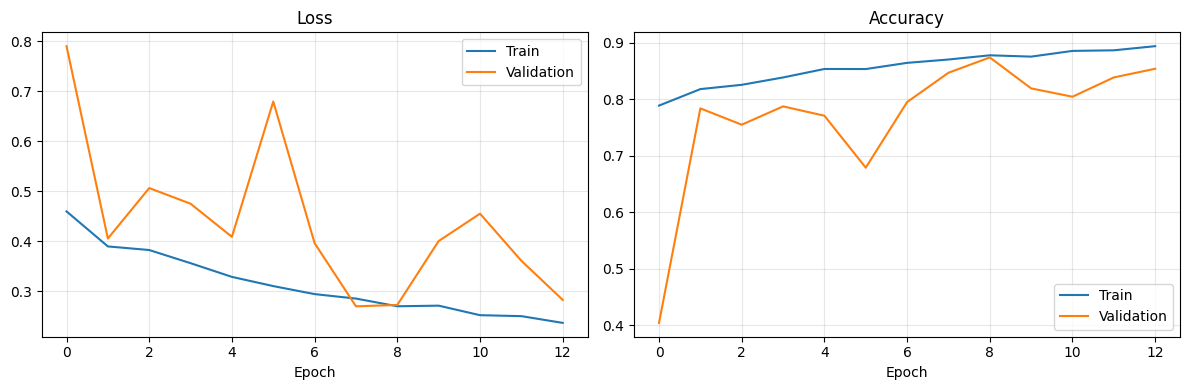

In [ ]:
h = history.history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h['loss'], label='Train'); axes[0].plot(h['val_loss'], label='Validation')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(h['accuracy'], label='Train'); axes[1].plot(h['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('cnn_training_curves.png', dpi=150); plt.show()


## 8. Evaluate on held-out source images

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
probs = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=CLASS_NAMES, digits=3, zero_division=0))


Test loss: 0.4311
Test accuracy: 0.8865

Classification report:
              precision    recall  f1-score   support

       Price      0.826     0.653     0.729       320
     Product      0.900     0.958     0.928      1046

    accuracy                          0.887      1366
   macro avg      0.863     0.806     0.829      1366
weighted avg      0.883     0.887     0.882      1366



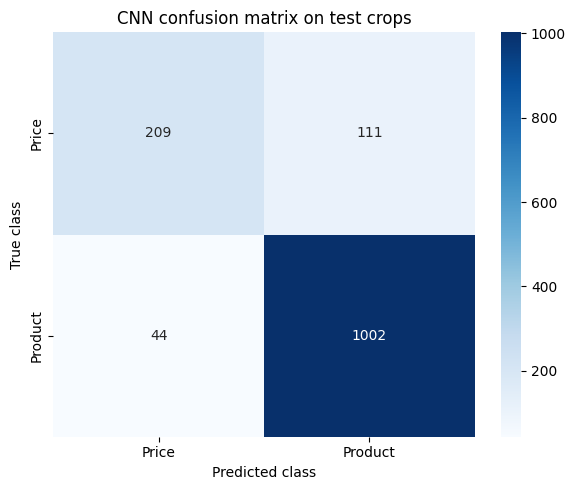

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted class'); plt.ylabel('True class'); plt.title('CNN confusion matrix on test crops')
plt.tight_layout(); plt.savefig('cnn_confusion_matrix.png', dpi=150); plt.show()


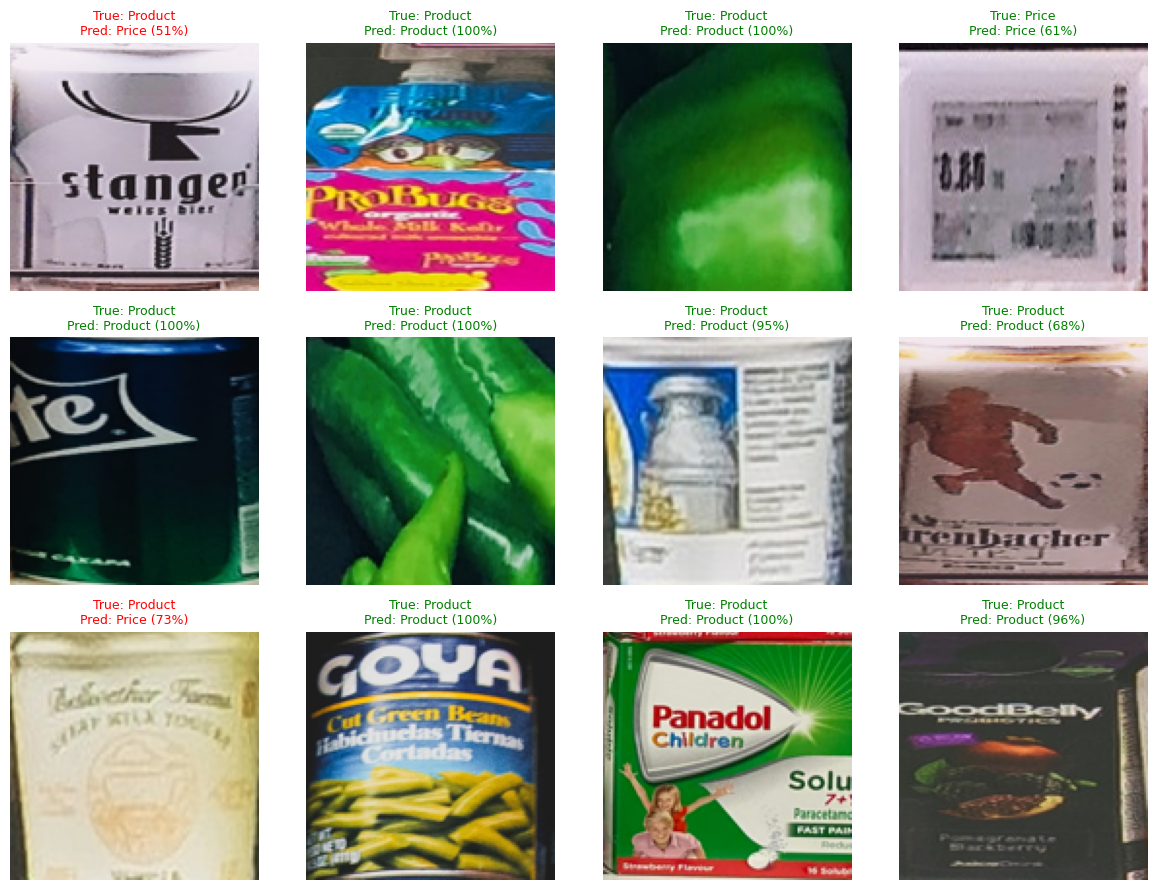

In [ ]:
rng = np.random.default_rng(SEED)
indices = rng.choice(len(X_test), size=min(12, len(X_test)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax in axes.ravel(): ax.axis('off')
for ax, i in zip(axes.ravel(), indices):
    ax.imshow(X_test[i].astype('uint8'))
    correct = y_pred[i] == y_test[i]
    ax.set_title(f'True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({probs[i].max():.0%})',
                 color='green' if correct else 'red', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.savefig('cnn_sample_predictions.png', dpi=150); plt.show()


## 9. Save model and results

In [ ]:
model.save('supermarket_shelf_cnn.keras')
summary = {
    'source_images_total': int(len(source_images)),
    'annotated_crops_total': int(len(records)),
    'price_crops': int(per_class['Price']),
    'product_crops': int(per_class['Product']),
    'train_crops': int(len(y_train)), 'validation_crops': int(len(y_val)), 'test_crops': int(len(y_test)),
    'epochs_run': int(len(history.history['loss'])),
    'training_minutes': round(training_minutes, 2),
    'test_loss': float(test_loss), 'test_accuracy': float(test_acc)
}
print(json.dumps(summary, indent=2))
with open('cnn_results_summary.json', 'w') as f: json.dump(summary, f, indent=2)
try:
    from google.colab import files
    for filename in ['supermarket_shelf_cnn.keras', 'cnn_training_curves.png', 'cnn_confusion_matrix.png', 'cnn_sample_predictions.png', 'cnn_results_summary.json']:
        if os.path.exists(filename): files.download(filename)
except ImportError:
    pass


{
  "source_images_total": 45,
  "annotated_crops_total": 11656,
  "price_crops": 1746,
  "product_crops": 9910,
  "train_crops": 8594,
  "validation_crops": 1696,
  "test_crops": 1366,
  "epochs_run": 13,
  "training_minutes": 2.97,
  "test_loss": 0.4310603439807892,
  "test_accuracy": 0.8865300416946411
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Save the trained CNN as `.joblib`

The artifact stores the CNN architecture and trained weights, along with class names, image size, and test metrics. TensorFlow/Keras is still required to reconstruct and run the network.

In [ ]:
import joblib

CNN_JOBLIB_PATH = 'supermarket_shelf_cnn.joblib'
cnn_artifact = {
    'architecture_json': model.to_json(),
    'weights': model.get_weights(),
    'class_names': list(CLASS_NAMES),
    'img_size': int(IMG_SIZE),
    'test_accuracy': float(test_acc),
    'test_loss': float(test_loss)
}
joblib.dump(cnn_artifact, CNN_JOBLIB_PATH, compress=3)
print(f'Saved {CNN_JOBLIB_PATH} ({os.path.getsize(CNN_JOBLIB_PATH)/1e6:.2f} MB)')



## 11. Inference using the saved `.joblib` model

The classifier operates on annotated/cropped image regions. For a full shelf photograph, provide pixel-coordinate bounding boxes for the regions to classify; object detection is not part of this CNN.

In [ ]:
def load_cnn_joblib(path=CNN_JOBLIB_PATH):
    artifact = joblib.load(path)
    net = keras.models.model_from_json(artifact['architecture_json'])
    net.set_weights(artifact['weights'])
    return net, artifact

def preprocess_inference_crop(image_or_path, size):
    if isinstance(image_or_path, (str, os.PathLike)):
        image = Image.open(image_or_path)
    else:
        image = image_or_path
    image = image.convert('RGB').resize((size, size))
    return np.asarray(image, dtype='uint8')

def predict_cnn_crops(crops, net, artifact):
    batch = np.stack([
        preprocess_inference_crop(crop, artifact['img_size'])
        for crop in crops
    ])
    probabilities = net.predict(batch, verbose=0)
    results = []
    for row in probabilities:
        idx = int(np.argmax(row))
        results.append({
            'predicted_class': artifact['class_names'][idx],
            'confidence': float(row[idx]),
            'class_probabilities': {
                name: float(value)
                for name, value in zip(artifact['class_names'], row)
            }
        })
    return results

def predict_shelf_regions(shelf_image, boxes, net, artifact):
    image = Image.open(shelf_image).convert('RGB') if isinstance(
        shelf_image, (str, os.PathLike)
    ) else shelf_image.convert('RGB')
    crops = [image.crop(tuple(box)) for box in boxes]
    results = predict_cnn_crops(crops, net, artifact)
    for box, result in zip(boxes, results):
        result['bounding_box'] = tuple(box)
    return results

# Reload the saved model and verify that predictions are preserved
loaded_cnn, loaded_cnn_artifact = load_cnn_joblib()
reloaded_probabilities = loaded_cnn.predict(X_test, verbose=0)
print('Maximum reload probability difference:',
      float(np.max(np.abs(reloaded_probabilities - probs))))
print('Prediction agreement:',
      f"{100 * (reloaded_probabilities.argmax(axis=1) == y_pred).mean():.2f}%")

# Demonstrate inference on several held-out image crops
demo_count = min(5, len(X_test))
demo_images = [Image.fromarray(X_test[i].astype('uint8')) for i in range(demo_count)]
for i, result in enumerate(predict_cnn_crops(demo_images, loaded_cnn, loaded_cnn_artifact)):
    print(f"Crop {i}: {result['predicted_class']} "
          f"({result['confidence']:.1%})")

# Example: inference on selected regions of a complete shelf image.
# Replace the path and boxes with coordinates from your shelf photograph.
# shelf_path = '/content/supermarket_dataset/.../images/035.jpg'
# boxes = [(120, 80, 260, 300), (130, 310, 250, 345)]
# print(predict_shelf_regions(shelf_path, boxes, loaded_cnn, loaded_cnn_artifact))

try:
    from google.colab import files
    files.download(CNN_JOBLIB_PATH)
except ImportError:
    pass
